# Does starting position decide an F1 race?

**Question:** How much does where a driver starts decide where they finish, and does pit stop strategy change that?

**Data:** Race results and pit stop data from the FastF1 library (Jolpica/Ergast), 2019-2024. I left out drivers who didn't finish, and counted pit-lane starters as starting last.

**Method:** For every race I compared starting and finishing positions using Spearman rank correlation (1 means the finishing order matches the grid exactly). For 2023 I then compared drivers who made more or fewer pit stops than the rest of the field.

In [21]:
import time
import pandas as pd
import matplotlib.pyplot as plt
from fastf1.ergast import Ergast

ergast = Ergast()   

2019 done
2020 done
2021 done
2022 done


Request for URL https://api.jolpi.ca/ergast/f1/2023/15/results.json failed; using cached response
Traceback (most recent call last):
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests_cache\session.py", line 316, in _resend
    response.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests\models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 429 Client Error: Too Many Requests for url: https://api.jolpi.ca/ergast/f1/2023/15/results.json
Request for URL https://api.jolpi.ca/ergast/f1/2023/17/results.json failed; using cached response
Traceback (most recent call last):
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests_cache\session.py", line 316, in _resend
    response.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests\models.py", line 1167, in raise_for_status
    raise HTTPError(h

2023 done


Request for URL https://api.jolpi.ca/ergast/f1/2024/1/results.json failed; using cached response
Traceback (most recent call last):
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests_cache\session.py", line 316, in _resend
    response.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests\models.py", line 1167, in raise_for_status
    raise HTTPError(http_error_msg, response=self)
requests.exceptions.HTTPError: 429 Client Error: Too Many Requests for url: https://api.jolpi.ca/ergast/f1/2024/1/results.json
Request for URL https://api.jolpi.ca/ergast/f1/2024/3/results.json failed; using cached response
Traceback (most recent call last):
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests_cache\session.py", line 316, in _resend
    response.raise_for_status()
    ~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "C:\Users\palla\anaconda3\Lib\site-packages\requests\models.py", line 1167, in raise_for_status
    raise HTTPError(http

2024 done


,Season,Race,Corr_All,Corr_FinishersOnly,Drivers_Removed
0,2019,Australian Grand Prix,0.718797,0.850490,3
1,2019,Bahrain Grand Prix,0.622556,0.876471,4
2,2019,Chinese Grand Prix,0.696241,0.872549,3
3,2019,Azerbaijan Grand Prix,0.670181,0.897719,4
4,2019,Spanish Grand Prix,0.851128,0.938080,2


**How I measured it**

I used Spearman rank correlation to compare each driver's starting position with their finishing position. It only looks at the order, so a score near 1 means the finishing order closely followed the grid, and a score near 0 means there was little relationship.

I left out drivers who didn't finish (retired, disqualified, did not start and so on). A driver who crashes on lap 1 is classified last whatever their grid slot, which hides how well the grid predicted the result for everyone else. `Corr_All` keeps them in and `Corr_FinishersOnly` takes them out. Drivers who started from the pit lane are counted as starting last.

In [16]:
# same circuit, different names in different years
races["Circuit"] = races["Race"].replace({
    "Brazilian Grand Prix": "São Paulo Grand Prix",
    "Mexican Grand Prix": "Mexico City Grand Prix",
})

# average correlation per season
print(races.groupby("Season")["Corr_FinishersOnly"].mean().round(2))

# average per circuit, keeping circuits with at least 3 races
circuits = races.groupby("Circuit")["Corr_FinishersOnly"].agg(["mean", "count"])
circuits = circuits[circuits["count"] >= 3].sort_values("mean")
circuits

Season
2019    0.75
2020    0.77
2021    0.76
2022    0.74
2023    0.71
2024    0.81
Name: Corr_FinishersOnly, dtype: float64


,mean,count
Circuit,,
São Paulo Grand Prix,0.587598,5
Russian Grand Prix,0.620148,3
Italian Grand Prix,0.681282,6
Hungarian Grand Prix,0.711726,6
Qatar Grand Prix,0.721217,3
Canadian Grand Prix,0.723368,4
Emilia Romagna Grand Prix,0.736269,4
Singapore Grand Prix,0.747902,4
United States Grand Prix,0.753768,5


**What this shows**

Average correlation by season ranged from 0.71 to 0.81, indicating a consistently strong relationship between grid position and finishing position across all six seasons. There was no clear long-term upward or downward trend. Circuit averages were only calculated for tracks that hosted at least three races during the period to reduce the influence of small sample sizes. Race names that changed over time, such as the Brazilian and Mexican Grands Prix, were merged into São Paulo and Mexico City respectively.


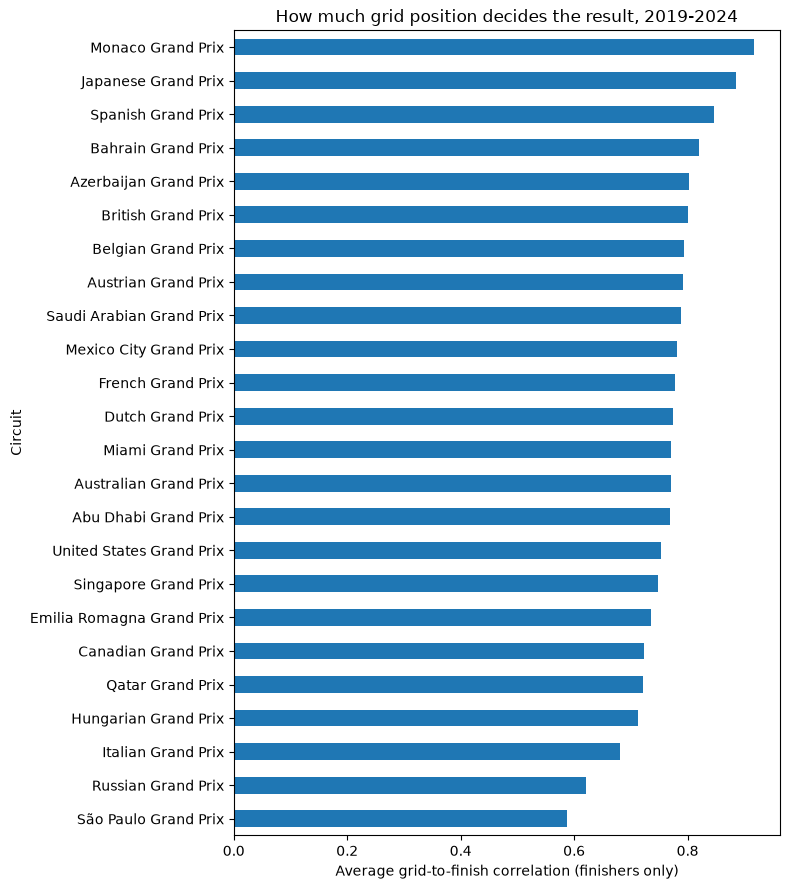

In [17]:
circuits["mean"].plot(kind="barh", figsize=(8, 9))
plt.xlabel("Average grid-to-finish correlation (finishers only)")
plt.title("How much grid position decides the result, 2019-2024")
plt.tight_layout()
plt.savefig("circuit_grid_dependence.png", dpi=150)
plt.show()

**Which circuits depend most on the grid**

Across the 2019-2024 seasons, qualifying position was consistently a strong predictor of race finishing position, with average circuit correlations ranging from 0.59 to 0.92. Monaco, Japan and Spain showed the strongest relationships between grid position and finishing order, while São Paulo, Russia and Italy showed the weakest. Although the strength of the relationship varied between circuits, most tracks recorded correlations above 0.70, indicating that starting position remained an important factor in determining race outcomes. This analysis identifies where grid position appears to matter most, but further investigation would be required to explain why these differences occur between circuits.

In [23]:
tables = []   

for rnd in range(1, 23):
    data = ergast.get_race_results(season=2023, round=rnd)
    res = data.content[0].copy()
    res["Race"] = data.description["raceName"].iloc[0]

    # count pit stops per driver and add them to the results
    stops = ergast.get_pit_stops(season=2023, round=rnd, limit=100)
    stop_counts = stops.content[0].groupby("driverId").size()
    res["Stops"] = res["driverId"].map(stop_counts).fillna(0)

    res.loc[res["grid"] == 0, "grid"] = len(res)

    # keep finishers only
    res = res[res["status"].isin(["Finished", "Lapped"]) | res["status"].str.startswith("+")].copy()

    # places gained = start position minus finish position
    res["PositionsGained"] = res["grid"] - res["position"]

    # compare each driver's stops with the most common number in that race
    res["StopsVsTypical"] = res["Stops"] - res["Stops"].mode().iloc[0]

    tables.append(res[["Race", "driverCode", "grid", "position", "PositionsGained", "Stops", "StopsVsTypical"]])
    time.sleep(2)

strategy = pd.concat(tables, ignore_index=True)   # stack the 22 tables into one
strategy.head()

,Race,driverCode,grid,position,PositionsGained,Stops,StopsVsTypical
0,Bahrain Grand Prix,VER,1,1,0,2.0,0.0
1,Bahrain Grand Prix,PER,2,2,0,2.0,0.0
2,Bahrain Grand Prix,ALO,5,3,2,2.0,0.0
3,Bahrain Grand Prix,SAI,4,4,0,2.0,0.0
4,Bahrain Grand Prix,HAM,7,5,2,2.0,0.0


**How I measured strategy**

To examine the relationship between pit-stop strategy and race progress, strategy was proxied by the number of pit stops made by each driver during the 2023 season. Drivers were compared with the most common stop count in each race and classified as making fewer, typical or more stops than the majority of the field. Positions gained were calculated as starting position minus finishing position, with positive values indicating movement forwards through the field.

In [24]:
def strategy_label(x):
    if x < 0:
        return "Fewer stops"
    elif x > 0:
        return "More stops"
    else:
        return "Typical"

def grid_band(g):
    if g <= 5:
        return "Front (1-5)"
    elif g <= 12:
        return "Mid (6-12)"
    else:
        return "Back (13+)"

strategy["Strategy"] = strategy["StopsVsTypical"].apply(strategy_label)
strategy["GridBand"] = strategy["grid"].apply(grid_band)

# average places gained for each group
strategy.groupby(["GridBand", "Strategy"])["PositionsGained"].agg(["mean", "median", "std", "count"]).round(2)

mean  median   std  count
GridBand    Strategy                              
Back (13+)  Fewer stops  3.71     4.0  4.27      7
            More stops   3.00     3.0  4.48     39
            Typical      3.82     4.0  3.82     94
Front (1-5) Fewer stops -3.80    -4.0  3.27      5
            More stops  -4.00    -2.0  5.73     11
            Typical     -0.88     0.0  2.31     81
Mid (6-12)  Fewer stops  0.36     1.0  4.22     14
            More stops  -2.07    -2.0  3.92     15
            Typical      0.60     0.5  3.66    108

**Pit-Stop Strategy and Positions Gained**

To control for the fact that drivers starting further back have more opportunities to gain positions, drivers were grouped into front (1-5), midfield (6-12) and back (13+) grid bands. Across all three groups, the typical pit-stop strategy generally performed as well as or better than strategies involving more or fewer stops than the race norm. 

Among front-running drivers, those following the typical strategy lost less track position on average (-0.88 places) than drivers making more (-4.00) or fewer (-3.80) stops, although the sample sizes for the alternative strategies were small. For midfield starters, typical strategies again produced the best average outcome (+0.60 places), while drivers making additional stops lost positions on average (-2.07). Among back-markers, all strategy groups gained positions on average, suggesting that starting position may have had a greater influence on opportunities for place gains than pit-stop strategy alone.

Overall, there is little evidence that making more or fewer pit stops than the race norm consistently improved race position. The typical strategy produced comparable or better outcomes in most grid bands, although the small number of drivers using alternative strategies means the results should be interpreted cautiously.

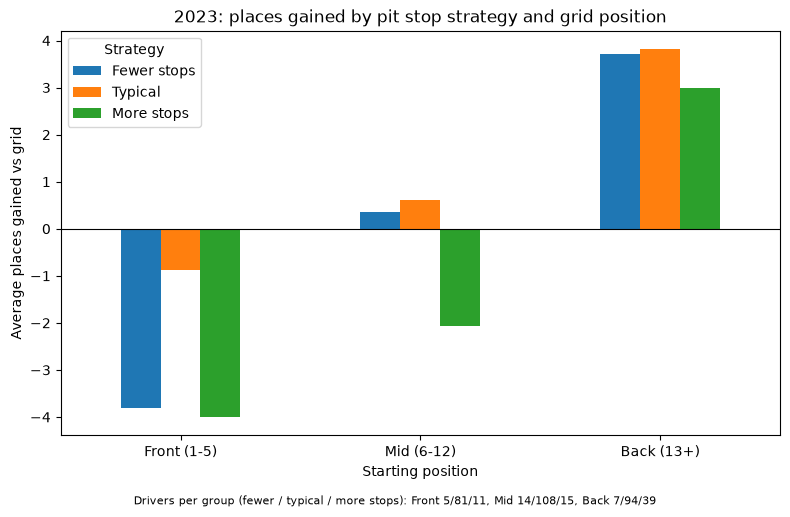

In [22]:
chart = strategy.groupby(["GridBand", "Strategy"])["PositionsGained"].mean().unstack()
chart = chart.loc[["Front (1-5)", "Mid (6-12)", "Back (13+)"], ["Fewer stops", "Typical", "More stops"]]

chart.plot(kind="bar", figsize=(8, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Average places gained vs grid")
plt.xlabel("Starting position")
plt.title("2023: places gained by pit stop strategy and grid position")
plt.xticks(rotation=0)
plt.figtext(0.5, -0.02, "Drivers per group (fewer / typical / more stops): Front 5/81/11, Mid 14/108/15, Back 7/94/39",
            ha="center", fontsize=8)
plt.tight_layout()
plt.savefig("strategy_by_grid.png", dpi=150, bbox_inches="tight")
plt.show()

**What the chart shows**

Across all three grid bands, drivers using the typical number of pit stops generally matched or outperformed those using fewer or more stops. The largest difference appears among front-running drivers, where alternative strategies were associated with larger average position losses. However, only 5 drivers used fewer stops and 11 used more stops, so this should be treated as an indication of a possible pattern rather than firm evidence.

**Limitations**

1. Pit-stop count is only a proxy for strategy. Tyre compounds, pit timing and stint lengths may have a greater effect on performance but were not included in this analysis.
2. Additional pit stops are often caused by damage, punctures, penalties or safety-car decisions, so the analysis identifies associations rather than causal effects.
3. Some groups contain relatively few observations (5-15 drivers), and the analysis is limited to the 2023 season.

Overall, there is little evidence that deviating from the most common pit-stop strategy consistently improved finishing position. Drivers following the typical strategy generally achieved similar or better outcomes across all grid bands. However, the small sample sizes for alternative strategies and the simplified measure of strategy mean that these results should be considered exploratory rather than definitive.

